# 07 · Batching, devices and persistence

Four practical features: answering many queries in one batched call, choosing
and moving the device, saving and loading a fitted model, and loading a
Bayesian network from a `.bif` file.

- **NBN API:** `query_batch` vs a loop of `query`; `device="auto"`,
  `model.to(...)`, `model.device`, `nbn.utils.device.resolve_device`,
  `accelerator_summary`; `save` / `NeuralBayesianNetwork.load`;
  `NeuralBayesianNetwork.from_bif` and `state_names`.
- **Runtime:** about 15 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
  Section 4 (`from_bif`) also needs `pgmpy` (`pip install pgmpy`, or the `bench` extra).
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Two networks:

1. **Asia**, the classic 8-node discrete network, read from the file
   `tests/data/bnlearn/asia.bif` that ships with the repository.
2. A **hybrid** network: `Rain -> Sprinkler`, `(Rain, Sprinkler) -> WetGrass`,
   a continuous `Soil | WetGrass` (`N(-1, 0.5^2)` when dry, the bimodal
   `0.5 N(1.5, 0.3^2) + 0.5 N(3, 0.3^2)` when wet), and a continuous
   `Growth | Soil ~ N(0.8 Soil + 0.5, 0.3^2)`.

In [1]:
import copy
import itertools
import math
import os
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    LikelihoodWeightingEngine,
    MDNMechanism,
    NeuralBayesianNetwork,
    TensorVariableElimination,
    seed_all,
)
from nbn.mechanisms import NormalizingFlowMechanism
from nbn.utils.device import accelerator_summary, resolve_device, synchronize
from _figures import BLUE, ORANGE, AQUA, VERMILLION, SKY, MAGENTA, YELLOW, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The two networks

`from_bif` needs `pgmpy` to parse the file; section 4 looks at the result in
detail.  The `.bif` file is found relative to this notebook (it lives in the
repository's `tests/data/bnlearn/`).  The hybrid network is fitted from 5000
simulated rows.

In [2]:
def find_bif(name: str) -> Path | None:
    """Look for tests/data/bnlearn/<name> in this folder and its parents."""
    for root in [Path.cwd(), *Path.cwd().parents]:
        candidate = root / "tests" / "data" / "bnlearn" / name
        if candidate.exists():
            return candidate
    return None


try:
    with warnings.catch_warnings():
        # Importing pgmpy emits a FutureWarning about its own reorganisation and a
        # tqdm warning about notebook progress bars; neither concerns this notebook.
        warnings.simplefilter("ignore")
        import pgmpy.inference  # noqa: F401
    HAVE_PGMPY = True
except ImportError:
    HAVE_PGMPY = False
if not HAVE_PGMPY:
    raise ImportError("This notebook reads a .bif file, which needs pgmpy: pip install pgmpy")

ASIA_BIF = find_bif("asia.bif")
if ASIA_BIF is None:
    raise FileNotFoundError("asia.bif not found: run this notebook from a checkout of the repository.")
asia = NeuralBayesianNetwork.from_bif(str(ASIA_BIF), device=device)
print("asia:", asia)

H_EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
           ("WetGrass", "Soil"), ("Soil", "Growth")]
H_VARS = {"Rain": ("discrete", 2), "Sprinkler": ("discrete", 2), "WetGrass": ("discrete", 2),
          "Soil": ("continuous", 1), "Growth": ("continuous", 1)}
H_RAIN = torch.tensor([0.7, 0.3])
H_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])
H_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]], [[0.15, 0.85], [0.02, 0.98]]])


def normal_pdf(x, mean, std):
    return torch.exp(-0.5 * ((x - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))


def soil_pdf(x, wet: int):
    if wet:
        return 0.5 * normal_pdf(x, 1.5, 0.3) + 0.5 * normal_pdf(x, 3.0, 0.3)
    return normal_pdf(x, -1.0, 0.5)


def h_sample(n: int) -> dict:
    rain = torch.multinomial(H_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(H_SPRINKLER[rain, 1]).long()
    wet = torch.bernoulli(H_WET[rain, sprinkler, 1]).long()
    soil_wet = torch.where(torch.rand(n) < 0.5, 3.0, 1.5) + 0.3 * torch.randn(n)
    soil = torch.where(wet == 1, soil_wet, -1.0 + 0.5 * torch.randn(n))
    growth = 0.8 * soil + 0.5 + 0.3 * torch.randn(n)
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet, "Soil": soil[:, None],
            "Growth": growth[:, None]}


def exact_rain_given_soil(soil: torch.Tensor) -> torch.Tensor:
    """P(Rain = 1 | Soil = soil) under the true hybrid network."""
    post = []
    for rain in (0, 1):
        total = 0.0
        for spr, wet in itertools.product((0, 1), repeat=2):
            total = total + H_RAIN[rain] * H_SPRINKLER[rain, spr] * H_WET[rain, spr, wet] * soil_pdf(soil, wet)
        post.append(total)
    return post[1] / (post[0] + post[1])


seed_all(0)
hybrid = NeuralBayesianNetwork(H_EDGES, H_VARS, device=device)
hybrid.set_mechanism("Soil", MDNMechanism(num_components=3))
hybrid.set_mechanism("Growth", NormalizingFlowMechanism())
hybrid.auto_mechanisms()
hybrid.fit(h_sample(5000), consolidate=False)
print("hybrid:", hybrid)
print("mechanisms:", {n: type(m).__name__ for n, m in hybrid.mechanisms.items()})

asia: NeuralBayesianNetwork(nodes=8, edges=8, fitted_mechanisms=8, device=cpu)


hybrid: NeuralBayesianNetwork(nodes=5, edges=5, fitted_mechanisms=5, device=cpu)
mechanisms: {'Soil': 'MDNMechanism', 'Growth': 'NormalizingFlowMechanism', 'Rain': 'CategoricalTableMechanism', 'Sprinkler': 'CategoricalTableMechanism', 'WetGrass': 'CategoricalTableMechanism'}


## 1. `query_batch` against a Python loop

`query_batch` takes one evidence row per query (tensors of shape `[B]`) and
answers all B queries in one call.  The loop calls `query` B times.  We time
both for B from 1 to 4096:

- **VE on Asia:** `P(lung | xray, dysp, smoke)` with evidence rows drawn from
  the network itself.
- **LW on the hybrid network:** `P(Rain | Soil = s)` for B values of `s`,
  1024 particles per query.  The LW loop is timed up to B = 1024 only (larger
  loops take too long for this notebook).

Each batched time is the best of 3 calls (one call for LW with B > 256); each loop is timed once.
`synchronize(device)` waits for queued GPU work before the clock stops (a no-op on the CPU).

In [3]:
def best_of(fn, repeats: int = 3) -> float:
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        synchronize(device)          # wait for queued GPU work; a no-op on the CPU
        best = min(best, time.perf_counter() - start)
    return best


BATCH = [1, 4, 16, 64, 256, 1024, 4096]
ve = TensorVariableElimination()
lw = LikelihoodWeightingEngine(n_samples=1024)

seed_all(1)
asia_rows = asia.sample(max(BATCH))
EV_NODES = ["xray", "dysp", "smoke"]
asia_ev = {k: asia_rows[k].reshape(-1).long() for k in EV_NODES}
soil_ev = torch.empty(max(BATCH)).uniform_(-3.0, 4.5)

timing = {"VE, batched": [], "VE, loop": [], "LW, batched": [], "LW, loop": []}
asia.query_batch(["lung"], {k: v[:2] for k, v in asia_ev.items()}, engine=ve)   # warm-up
for b in BATCH:
    ev = {k: v[:b] for k, v in asia_ev.items()}
    timing["VE, batched"].append(best_of(lambda ev=ev: asia.query_batch(["lung"], ev, engine=ve)))
    start = time.perf_counter()
    looped = torch.stack([asia.query(["lung"], {k: int(v[i]) for k, v in ev.items()}, engine=ve)
                          for i in range(b)])
    synchronize(device)
    timing["VE, loop"].append(time.perf_counter() - start)
batched = asia.query_batch(["lung"], asia_ev, engine=ve)
print(f"VE: largest |batched - looped| over {max(BATCH)} queries = "
      f"{float((batched - looped).abs().max()):.1e}")

for b in BATCH:
    ev = {"Soil": soil_ev[:b, None]}
    timing["LW, batched"].append(best_of(lambda ev=ev: hybrid.query_batch(["Rain"], ev, engine=lw),
                                         repeats=3 if b <= 256 else 1))
    if b <= 1024:
        start = time.perf_counter()
        lw_looped = torch.stack([hybrid.query(["Rain"], {"Soil": float(s)}, engine=lw)
                                 for s in soil_ev[:b]])
        synchronize(device)
        timing["LW, loop"].append(time.perf_counter() - start)

seed_all(2)
lw_batched = hybrid.query_batch(["Rain"], {"Soil": soil_ev[:1024, None]}, engine=lw)
truth = exact_rain_given_soil(soil_ev[:1024])
print("LW, 1024 queries: mean |P(Rain=1) - exact|:",
      f"batched {float((lw_batched[:, 1].cpu() - truth).abs().mean()):.3f},",
      f"looped {float((lw_looped[:, 1].cpu() - truth).abs().mean()):.3f}")

print(f"\n{'B':>6s}" + "".join(f"{k:>14s}" for k in timing) + f"{'VE speed-up':>13s}{'LW speed-up':>13s}")
for i, b in enumerate(BATCH):
    row = [timing[k][i] if i < len(timing[k]) else float("nan") for k in timing]
    print(f"{b:6d}" + "".join(f"{1000 * t:12.1f}ms" if t == t else f"{'-':>14s}" for t in row)
          + f"{row[1] / row[0]:12.0f}x" + (f"{row[3] / row[2]:12.0f}x" if i < len(timing['LW, loop']) else ""))

VE: largest |batched - looped| over 4096 queries = 0.0e+00


LW, 1024 queries: mean |P(Rain=1) - exact|: batched 0.014, looped 0.014

     B   VE, batched      VE, loop   LW, batched      LW, loop  VE speed-up  LW speed-up
     1         0.1ms         0.1ms         0.6ms         0.6ms           1x           1x
     4         0.2ms         0.4ms         1.3ms         2.5ms           3x           2x
    16         0.2ms         1.5ms         3.5ms         9.1ms          10x           3x
    64         0.2ms         6.0ms         9.7ms        33.4ms          36x           3x
   256         0.2ms        23.5ms        34.6ms       135.0ms         135x           4x
  1024         0.4ms        94.2ms       140.9ms       545.4ms         269x           4x
  4096         0.9ms       377.9ms       646.6ms             -         429x


Left: wall-clock time against the number of queries (both axes logarithmic).
Right: the speed-up, loop time divided by batched time.

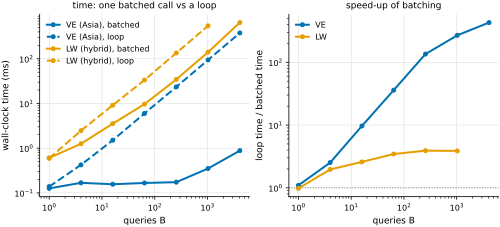

In [4]:
fig, (ax_t, ax_s) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
styles = {"VE, batched": (BLUE, "-"), "VE, loop": (BLUE, "--"),
          "LW, batched": (ORANGE, "-"), "LW, loop": (ORANGE, "--")}
for name, times in timing.items():
    color, ls = styles[name]
    ax_t.plot(BATCH[:len(times)], 1000 * np.array(times), "o", ls=ls, color=color, lw=2, ms=4,
              label=name.replace("VE", "VE (Asia)").replace("LW", "LW (hybrid)"))
ax_t.set(xscale="log", yscale="log", xlabel="queries B", ylabel="wall-clock time (ms)",
         title="time: one batched call vs a loop")
ax_t.legend(frameon=False, fontsize=8)
for eng, color in (("VE", BLUE), ("LW", ORANGE)):
    loop, batch = np.array(timing[f"{eng}, loop"]), np.array(timing[f"{eng}, batched"][:len(timing[f"{eng}, loop"])])
    ax_s.plot(BATCH[:len(loop)], loop / batch, "o-", color=color, lw=2, ms=4, label=eng)
ax_s.axhline(1, color=GREY, lw=1, ls=":")
ax_s.set(xscale="log", yscale="log", xlabel="queries B", ylabel="loop time / batched time",
         title="speed-up of batching")
ax_s.legend(frameon=False, fontsize=8)
save(fig, "07_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Left: wall-clock time to answer `B` queries with one `query_batch` call (solid) and with a loop of `query` (dashed), for VE on Asia and LW on the hybrid network (log-log). Right: the ratio of the two; dotted: no speed-up. One timing per point.

- **VE:** the batched call stays near or below 1 ms up to 4096 queries.  The
  loop costs about 0.1 ms per query and grows linearly, so batching is
  hundreds of times faster at B = 4096.  The batched and looped answers are
  identical.
- **LW:** the work is (queries x particles), so the batched time also grows
  with B.  Batching removes the fixed cost of each call, which gives a
  speed-up of only a few times here.  The accuracy is the same: both are about
  0.014 away from the exact `P(Rain = 1 | Soil)` on average.

## 2. Devices

`resolve_device("auto")` picks CUDA, then Apple MPS, then the CPU, and
`accelerator_summary()` names the accelerator it would pick on this machine.
A model is built on a device (`device=` in the constructor, `"auto"` by
default) and moved with `model.to(...)`; `model.device` tells where it lives.
Data and evidence can stay on the CPU: NBN moves them to the model's device.

This notebook was run with `NBN_EXAMPLES_DEVICE=cpu`, so the comparison below
is skipped in the stored output.  Run it on a machine with an accelerator (and
without that variable) to compare the two devices.

In [5]:
print("auto would pick:", resolve_device("auto"), "|", accelerator_summary())
print("this notebook uses:", device)

if device.type == "cpu":
    print("no accelerator in use: nothing to compare (the models are on the CPU).")
else:
    asia_cpu = copy.deepcopy(asia).to("cpu")
    print("asia.device:", asia.device, "-> copy moved with .to('cpu'):", asia_cpu.device)
    on_acc = asia.query_batch(["lung"], asia_ev, engine=ve)
    on_cpu = asia_cpu.query_batch(["lung"], asia_ev, engine=ve)
    print(f"VE, {len(on_cpu)} queries: largest |{device.type} - cpu| = "
          f"{float((on_acc.cpu() - on_cpu).abs().max()):.1e}")
    hybrid_cpu = copy.deepcopy(hybrid).to("cpu")
    rows = h_sample(1000)
    with torch.no_grad():
        lp_acc, lp_cpu = hybrid.log_prob(rows).cpu(), hybrid_cpu.log_prob(rows)
    print(f"hybrid log_prob, 1000 rows: largest |{device.type} - cpu| = "
          f"{float((lp_acc - lp_cpu).abs().max()):.1e}")

auto would pick: mps | mps (Apple Metal; float64 unavailable, accumulations run in float32)
this notebook uses: cpu
no accelerator in use: nothing to compare (the models are on the CPU).


## 3. `save` and `load`

`model.save(path)` writes the graph, the variable types and the fitted
mechanisms to one `.pt` file; `NeuralBayesianNetwork.load(path)` returns a model
that is ready to query (pass `map_location=` to choose its device).  We save
both networks to a temporary folder, load them back and compare their answers.
Loading runs pickled code, so load only files you trust.

In [6]:
with tempfile.TemporaryDirectory() as folder:
    asia.save(os.path.join(folder, "asia.pt"))
    hybrid.save(os.path.join(folder, "hybrid.pt"))
    sizes = {name: os.path.getsize(os.path.join(folder, f"{name}.pt")) / 1024 for name in ("asia", "hybrid")}
    asia2 = NeuralBayesianNetwork.load(os.path.join(folder, "asia.pt"), map_location=str(device))
    hybrid2 = NeuralBayesianNetwork.load(os.path.join(folder, "hybrid.pt"), map_location=str(device))
print("file sizes (KiB):", {k: round(v, 1) for k, v in sizes.items()})
print("loaded:", hybrid2, "| state_names kept:", asia2.state_names == asia.state_names)

diff_ve = float((asia2.query_batch(["lung"], asia_ev, engine=ve)
                 - asia.query_batch(["lung"], asia_ev, engine=ve)).abs().max())
rows = h_sample(2000)
with torch.no_grad():
    lp_before, lp_after = hybrid.log_prob(rows), hybrid2.log_prob(rows)
diff_lp = float((lp_after - lp_before).abs().max())
seed_all(3)
before = hybrid.query_batch(["Rain"], {"Soil": soil_ev[:256, None]}, engine=lw)
seed_all(3)
after = hybrid2.query_batch(["Rain"], {"Soil": soil_ev[:256, None]}, engine=lw)
diff_lw = float((after - before).abs().max())
print(f"Asia, VE, {len(asia_ev['xray'])} queries:        largest difference {diff_ve:.1e}")
print(f"hybrid, log_prob of 2000 rows:   largest difference {diff_lp:.1e}")
print(f"hybrid, LW (same seed), 256 queries: largest difference {diff_lw:.1e}")

file sizes (KiB): {'asia': 9.5, 'hybrid': 171.2}
loaded: NeuralBayesianNetwork(nodes=5, edges=5, fitted_mechanisms=5, device=cpu) | state_names kept: True
Asia, VE, 4096 queries:        largest difference 0.0e+00
hybrid, log_prob of 2000 rows:   largest difference 0.0e+00
hybrid, LW (same seed), 256 queries: largest difference 0.0e+00


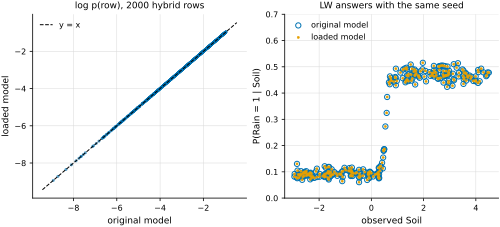

In [7]:
fig, (ax_l, ax_q) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_l.scatter(to_numpy(lp_before), to_numpy(lp_after), s=6, color=BLUE, alpha=0.6)
lims = [float(lp_before.min()) - 0.5, float(lp_before.max()) + 0.5]
ax_l.plot(lims, lims, color=INK, lw=1, ls="--", label="y = x")
ax_l.set(xlabel="original model", ylabel="loaded model", title="log p(row), 2000 hybrid rows")
ax_l.legend(frameon=False, fontsize=8, loc="upper left")
ax_q.scatter(to_numpy(soil_ev[:256]), to_numpy(before[:, 1]), s=28, facecolors="none",
             edgecolors=BLUE, lw=1, label="original model")
ax_q.scatter(to_numpy(soil_ev[:256]), to_numpy(after[:, 1]), s=5, color=ORANGE, label="loaded model")
ax_q.set(xlabel="observed Soil", ylabel="P(Rain = 1 | Soil)", ylim=(0, 0.7),
         title="LW answers with the same seed")
ax_q.legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "07_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

Every answer of the loaded models equals the original exactly (largest
difference 0): the VE answers, the log-likelihood of 2000 rows, and the LW
answers drawn with the same seed.  The file stores the fitted mechanisms
themselves (here an MDN and a normalizing flow), not only the graph: about
10 KiB for Asia and about 170 KiB for the hybrid model.

## 4. `from_bif`: a network from a `.bif` file

`from_bif` builds a discrete network whose tables hold the file's CPTs
verbatim, so it is ready to query without fitting.  States are integer
indices; `state_names` maps each index back to the label in the file, so
`state_names["smoke"].index("yes")` is the index of `smoke = yes`.

We ask `P(lung = yes | evidence)` for six evidence sets and compare NBN's
exact VE answer with pgmpy's own variable elimination on the same file.

In [8]:
names = asia.state_names
print("variables:", list(names))
print("state_names['smoke']:", names["smoke"])
print("parents of dysp:", asia.dag.parents("dysp"))

QUERIES = [{}, {"smoke": "yes"}, {"smoke": "no"}, {"xray": "yes"},
           {"xray": "yes", "smoke": "yes"}, {"xray": "yes", "dysp": "yes", "smoke": "no"}]
from pgmpy.inference import VariableElimination  # noqa: E402
from pgmpy.readwrite import BIFReader  # noqa: E402

reference = VariableElimination(BIFReader(str(ASIA_BIF)).get_model())
yes = names["lung"].index("yes")
nbn_p, pgmpy_p = [], []
for q in QUERIES:
    ev = {k: names[k].index(v) for k, v in q.items()}
    nbn_p.append(float(asia.query(["lung"], ev, engine=ve)[yes]))
    factor = reference.query(["lung"], evidence=q or None, show_progress=False)
    pgmpy_p.append(float(factor.values[factor.state_names["lung"].index("yes")]))
labels = ["no evidence"] + [", ".join(f"{k}={v}" for k, v in q.items()) for q in QUERIES[1:]]
for label, a, b in zip(labels, nbn_p, pgmpy_p):
    print(f"P(lung=yes | {label:28s}) NBN {a:.6f}   pgmpy {b:.6f}")
print(f"largest difference: {max(abs(a - b) for a, b in zip(nbn_p, pgmpy_p)):.1e}")

variables: ['asia', 'tub', 'smoke', 'lung', 'bronc', 'either', 'xray', 'dysp']
state_names['smoke']: ['yes', 'no']
parents of dysp: ['bronc', 'either']
P(lung=yes | no evidence                 ) NBN 0.055000   pgmpy 0.055000
P(lung=yes | smoke=yes                   ) NBN 0.100000   pgmpy 0.100000
P(lung=yes | smoke=no                    ) NBN 0.010000   pgmpy 0.010000
P(lung=yes | xray=yes                    ) NBN 0.488711   pgmpy 0.488711
P(lung=yes | xray=yes, smoke=yes         ) NBN 0.645991   pgmpy 0.645991
P(lung=yes | xray=yes, dysp=yes, smoke=no) NBN 0.245793   pgmpy 0.245793
largest difference: 4.5e-08


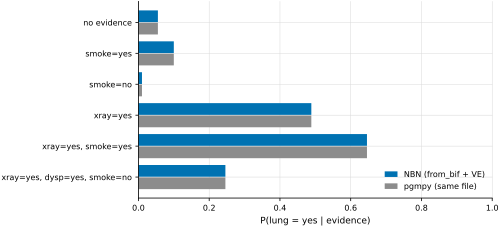

In [9]:
fig, ax = plt.subplots(figsize=(DOUBLE, 3.2))
y = np.arange(len(QUERIES))
ax.barh(y - 0.2, nbn_p, 0.38, color=BLUE, label="NBN (from_bif + VE)")
ax.barh(y + 0.2, pgmpy_p, 0.38, color=GREY, label="pgmpy (same file)")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set(xlabel="P(lung = yes | evidence)", xlim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "07_fig3")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** `P(lung = yes)` in the Asia network loaded from its BIF file, for six evidence sets: NBN with variable elimination (blue) and pgmpy on the same file (grey).

NBN and pgmpy agree to about 1e-7 (float32 rounding).  Evidence flows in both
directions: a positive x-ray raises `P(lung = yes)` from 0.055 to 0.49, and to
0.65 for a smoker.  Adding shortness of breath (`dysp = yes`) for a non-smoker
gives 0.25.